# Partie B — Exploration de 29 algorithmes de Machine Learning

**Variante distincte de la Partie A**, suivant les mêmes 29 rubriques et le même enchaînement de consignes. Les expériences utilisent d'autres jeux de données et des choix de paramètres différents.

- **Régression :** Diabetes, données réelles de scikit-learn (442 patients, 10 caractéristiques).
- **Classification :** Breast Cancer Wisconsin (569 observations, 30 caractéristiques) — exercice pédagogique, non diagnostic.
- **Clustering :** Wine (178 observations, 13 caractéristiques), avec projection ACP.
- **Réduction de dimension :** Digits (chiffres manuscrits, 64 caractéristiques) — autre jeu que Wine.
- **Renforcement :** Taxi-v3 de Gymnasium et bandit simulé à quatre bras.

**Exécutez les cellules dans l'ordre sur Google Colab.** Les jeux de données intégrés à scikit-learn sont publics et réels ; les bandits et environnements Gymnasium sont des simulations, et non des données observées du monde réel.

Sources : [scikit-learn datasets](https://scikit-learn.org/stable/datasets/real_world.html), [Gymnasium Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/).

# Travail demandé — Partie B (variante)

**Organisation :** binôme · **Public :** L3/Master · **Objectif :** savoir décrire, illustrer, situer et expérimenter **29 algorithmes** sur un second ensemble de cas.

Chaque algorithme doit faire l'objet de **quatre réponses** : présentation scientifique, schéma explicatif original, contexte d'utilisation et analyse de l'expérience. Les réponses ne sont pas fournies dans ce notebook : les codes servent de point de départ.

**Différence avec la Partie A :** nouveaux jeux de données (Diabetes, Breast Cancer, Wine et Digits), paramètres alternatifs, environnement Taxi et questions spécifiques sous chaque titre. Les 29 algorithmes et la structure générale restent identiques.

## Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)

**Q1 — Présentation (8 à 12 lignes).** Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la **définition de tous ses symboles**. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

**Q2 — Schéma original.** Dessiner un organigramme ou une figure scientifique montrant le chemin des données et le mécanisme de l'algorithme. Ajouter une légende et une explication du schéma. Indiquer la source si une figure extérieure est adaptée.

**Q3 — Contextes d'utilisation.** Décrire deux applications concrètes (au moins une en finance, gestion, logistique ou commerce international), les conditions nécessaires, un cas où la méthode est inappropriée et les métriques adaptées.

**Q4 — Analyse expérimentale.** Exécuter la cellule Python, citer la taille des données et les paramètres, interpréter les métriques et modifier **au moins un hyperparamètre** pour discuter son effet. Ne pas inventer de résultats.

**À ajouter par les étudiants sous chaque algorithme :** « Présentation », « Schéma explicatif », « Contexte d'utilisation », « Analyse et variation d'hyperparamètre ».

## Q0 — Données générées et visualisation

Les cellules d’initialisation chargent les jeux publics Diabetes, Breast Cancer, Wine et Digits, tandis que les cellules de renforcement génèrent des trajectoires par interaction avec Taxi-v3. Les tableaux `X_reg`, `X_cls`, `X_clu` et `X_images` contiennent respectivement les entrées utilisées par les familles de méthodes. Pour inspecter les données avant l’apprentissage, on peut afficher `shape`, les premières lignes et un nuage de points ; par exemple, pour Diabetes : `plt.scatter(X_reg[:, 2], y_reg, s=12, alpha=.6); plt.xlabel('Variable standardisée'); plt.ylabel('Cible'); plt.show()`. Cette visualisation est descriptive : elle ne remplace ni la séparation entraînement/test ni l’évaluation. Les bandits et Taxi-v3 sont des simulations d’interaction et ne doivent pas être présentés comme des observations réelles.


## Partie B — Validation finale sur des données publiques

**Q5. Provenance.** Choisir un jeu de données public distinct du cas de démonstration pour chaque famille de méthodes ; préciser la source officielle, l'URL, la date, les dimensions et la cible éventuelle. Une même base peut servir à plusieurs modèles compatibles.

**Q6. Prétraitement.** Identifier les variables manquantes, l'encodage, la standardisation et les éventuelles fuites de données. Ajuster les transformations sur l'entraînement uniquement quand il s'agit de prédire.

**Q7. Essais.** Tester tous les algorithmes adaptés aux données et à la tâche, avec un modèle de référence et un modèle avancé par famille. Séparer train/test (chronologiquement pour les séries temporelles). L'ACP, t-SNE et UMAP sont des outils exploratoires, pas des prédicteurs supervisés.

**Q8. Évaluation et analyse.** Comparer MAE/RMSE/R² (régression), F1/ROC-AUC/PR-AUC (classification, selon le déséquilibre), silhouette/stabilité (clustering), préservation locale (projections) et taux de réussite/récompense (renforcement).

**Note importante :** les bandits et Q-learning/SARSA nécessitent des environnements d'interaction. La démonstration DQN présente la cible de Bellman, **pas** un entraînement d'un réseau neuronal. Un DQN complet est un prolongement facultatif.

**Sources possibles :** [UCI](https://archive.ics.uci.edu/), [OpenML](https://www.openml.org/), [UN Comtrade](https://comtradeplus.un.org/), [Banque mondiale](https://data.worldbank.org/).

## Partie C — Restitution et barème

**Livrables :** (1) notebook complété pour les 29 algorithmes, (2) figures originales et paramètres expliqués, (3) expériences sur données publiques complémentaires, (4) rapport de synthèse de 5 à 8 pages, (5) soutenance en binôme.

**Barème /20 :** rigueur des présentations (5), qualité des 29 schémas (4), pertinence des cas d'usage (3), validité des expérimentations (5), reproductibilité et restitution (3).

**Intégrité :** ne pas confondre simulation et données observées ; citer les sources ; aucune valeur de performance ne doit être inventée ; justifier les changements d'hyperparamètres.

---
## Expérimentations Python de la Partie B

In [1]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [2]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)

Diabetes (442, 10) Breast cancer (569, 30) Wine (178, 2) Digits (1797, 64)


## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Régression supervisée. Elle approxime une cible continue par une combinaison affine des variables. Pour une observation x, la prédiction est ŷ = β₀ + Σⱼ βⱼxⱼ, où β₀ est l’interception, βⱼ les coefficients appris et xⱼ les caractéristiques. Les coefficients minimisent généralement la somme des carrés des résidus Σᵢ(yᵢ−ŷᵢ)². Les hyperparamètres sont ici peu nombreux ; le choix des variables, la régularisation éventuelle et la gestion des interactions sont déterminants. Atouts : modèle rapide et très interprétable ; bonne base de référence. Limites : sensibilité aux valeurs aberrantes et aux colinéarités ; incapacité à représenter une relation fortement non linéaire.

### Schéma explicatif

```text
Entrées x → estimation des coefficients β → combinaison affine → prédiction ŷ
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : prévoir une perte ou une demande à partir d’indicateurs économiques. Logistique : estimer un délai de livraison à partir de la distance, du poids et du transporteur. Les variables doivent être numériques ou encodées, et les distributions doivent être inspectées. Elle est peu appropriée pour une frontière très non linéaire ou des interactions nombreuses sans transformation des variables. Métriques : MAE, RMSE et R² ; analyser aussi les résidus.

### Analyse de l’expérience Python

Le code ajuste le modèle sur les données Diabetes d’entraînement puis calcule RMSE et R² sur le test. La taille est donnée par la cellule d’initialisation ; la séparation utilise 25 % de test et random_state=42. RMSE pénalise davantage les grandes erreurs, tandis que R² mesure la variance expliquée relativement à une prédiction constante. Une comparaison pertinente consiste à ajouter PolynomialFeatures ou à transformer une variable ; seule l’exécution fournit les valeurs numériques.


In [3]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

RMSE: 53.369566710321955 R²: 0.4849058889476756


## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Ridge est une régression linéaire régularisée par une pénalité L2. Elle minimise Σᵢ(yᵢ−xᵢᵀβ−β₀)² + αΣⱼβⱼ², où α est l’hyperparamètre de régularisation. Les β sont appris ; α est fixé avant l’apprentissage. La standardisation est importante car la pénalité compare les amplitudes des coefficients. Quand α augmente, les coefficients sont rapprochés de zéro sans être généralement annulés. Atouts : réduit la variance et l’instabilité due à la colinéarité ; reste rapide et relativement interprétable. Limites : ne sélectionne pas strictement les variables ; un α trop élevé sous-ajuste le modèle.

### Schéma explicatif

```text
Variables standardisées → pénalité L2 → coefficients rétrécis → prédiction continue
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : prédire une charge ou un rendement avec des indicateurs corrélés. Gestion : prévoir les coûts d’un portefeuille de projets. Il faut éviter la fuite d’information en ajustant le scaler sur l’entraînement. La méthode est peu appropriée si une sélection très parcimonieuse est nécessaire ou si la relation est très non linéaire. Métriques : MAE, RMSE, R² et évolution des coefficients.

### Analyse de l’expérience Python

Le pipeline standardise les variables puis ajuste Ridge(alpha=25) sur Diabetes. La sortie MAE représente l’erreur absolue moyenne sur le test. Pour étudier la question ciblée, comparer alpha=0.1, 25 et 10⁴ : une pénalisation très forte rend les prédictions proches d’une constante et dégrade généralement l’ajustement. Les valeurs exactes doivent être lues après exécution.


In [4]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.49082128021844


## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Lasso est une régression linéaire avec pénalité L1 : Σᵢ(yᵢ−ŷᵢ)² + αΣⱼ|βⱼ|. βⱼ sont les coefficients appris et α un hyperparamètre. La géométrie de L1 favorise des coefficients exactement nuls, ce qui réalise une sélection de variables. Le pipeline standardise d’abord les caractéristiques. Atouts : modèle parcimonieux et plus lisible ; utile avec beaucoup de variables. Limites : choix instable entre variables fortement corrélées ; risque de sous-ajustement lorsque α est trop grand. L’interception n’est habituellement pas pénalisée.

### Schéma explicatif

```text
Variables → standardisation → pénalité L1 → certains βⱼ=0 → prédiction
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Marketing : sélectionner les variables expliquant les ventes. Finance : retenir les indicateurs utiles à la prévision d’un risque. Il faut centrer/standardiser et valider α. Lasso est peu adapté si toutes les variables portent une information complémentaire ou si les relations sont non linéaires. Métriques : MAE, RMSE, R², nombre de coefficients non nuls et stabilité de sélection.

### Analyse de l’expérience Python

Le modèle utilise alpha=3 et max_iter=15000, puis affiche R² sur Diabetes. R² proche de 1 indique une bonne explication relative à la moyenne, mais un résultat faible peut rester utile si la cible est bruitée. Comparer alpha=0.1, 3 et 30 permet d’observer le compromis biais-parcimonie ; compter les coefficients nuls est indispensable pour analyser la sélection.


In [5]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.5013056660042327


## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

La régression polynomiale transforme les variables en monômes et interactions, puis applique une régression linéaire dans cet espace enrichi. Pour un degré d, la prédiction combine des termes xⱼ, xⱼ² et interactions jusqu’à d. Les coefficients sont appris ; degree et la régularisation Ridge(alpha) sont des hyperparamètres. Atouts : représente des courbures ; reste compatible avec des outils linéaires. Limites : le nombre de termes croît rapidement ; risque de surajustement et de forte sensibilité à l’échelle des variables. La régularisation et la validation sont donc essentielles.

### Schéma explicatif

```text
x → expansion polynomiale → régularisation Ridge → surface courbe → ŷ
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Commerce : modéliser une demande présentant des effets de seuil. Logistique : représenter un coût qui augmente de façon non linéaire avec la distance et le volume. Elle est peu appropriée avec beaucoup de variables et un degré élevé sans budget de calcul ni validation. Métriques : MAE, RMSE, R² et écart train-test.

### Analyse de l’expérience Python

Le pipeline applique StandardScaler, PolynomialFeatures(degree=2) puis Ridge(alpha=60). La sortie est la MAE sur le test Diabetes. Pour étudier la croissance dimensionnelle, comparer degree=1, 2 et 3 ; pour degree=2, comparer alpha=1 et 60. Une amélioration sur le train mais une dégradation sur le test signale un surajustement.


In [6]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 41.24579873763898


## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Un arbre de régression partitionne récursivement l’espace des variables en régions et prédit, dans chaque feuille, une valeur moyenne des observations. Une séparation est choisie pour réduire l’erreur quadratique intra-nœud. Les paramètres appris sont les seuils et la structure ; max_depth et min_samples_leaf sont des hyperparamètres. Atouts : capture les non-linéarités et ne nécessite pas de standardisation ; interprétation par règles. Limites : instabilité aux variations des données et surajustement facile ; prédiction par morceaux constante.

### Schéma explicatif

```text
Données → seuil xⱼ<t → sous-arbres → feuille → moyenne prédite
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : segmenter une demande de crédit selon revenus et historique. Logistique : estimer un délai par règles de distance, poids et priorité. Peu approprié si une extrapolation lisse est nécessaire. Métriques : MAE, RMSE, R² et comparaison train/test ; visualiser l’arbre.

### Analyse de l’expérience Python

Le modèle est limité à max_depth=3 et min_samples_leaf=8. Il affiche R² sur le test Diabetes. Comparer avec une profondeur illimitée ou une feuille minimale plus petite montre souvent une hausse de performance d’entraînement accompagnée d’une variance accrue. Les métriques numériques doivent provenir de l’exécution, pas d’une estimation théorique.


In [7]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.4314003646672102


## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Une forêt aléatoire agrège de nombreux arbres entraînés sur des échantillons bootstrap et des sous-ensembles aléatoires de variables. La prédiction est la moyenne des prédictions des arbres : ŷ=(1/T)Σₜfₜ(x), avec T le nombre d’arbres. Les arbres apprennent leur structure ; n_estimators, profondeur et min_samples_leaf sont des hyperparamètres. Atouts : réduit la variance d’un arbre ; capture les interactions sans mise à l’échelle. Limites : modèle plus lourd et moins lisible ; extrapole mal hors de la plage observée.

### Schéma explicatif

```text
Bootstrap + sous-ensemble de variables → arbres diversifiés → moyenne → ŷ
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : score de risque non linéaire. Logistique : prévision de volumes ou de délais avec variables hétérogènes. Peu appropriée si l’explicabilité réglementaire doit être strictement locale et simple. Métriques : MAE, RMSE, R², temps de calcul et importance/permutation.

### Analyse de l’expérience Python

Le code entraîne 120 arbres avec min_samples_leaf=4 et calcule la MAE sur le test. Le bootstrap et la moyenne stabilisent la prédiction, mais n’impliquent pas la causalité. Comparer n_estimators=20, 120 et 300 ou min_samples_leaf=1 et 8 documente l’effet du coût et de la variance.


In [8]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 42.58294190565993


## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Le gradient boosting construit séquentiellement des arbres faibles : chaque nouvel arbre approxime le résidu ou le gradient de la fonction de perte. La prédiction s’écrit Fₘ(x)=Fₘ₋₁(x)+ηhₘ(x), avec η le learning rate et hₘ l’arbre ajouté. max_iter et la taille des feuilles sont des hyperparamètres. Atouts : excellente capacité à modéliser des non-linéarités ; pertes et régularisations flexibles. Limites : entraînement séquentiel plus lent ; sensibilité au réglage et au surajustement.

### Schéma explicatif

```text
Prédiction initiale → résidus/gradient → nouvel arbre → ajout pondéré → répétition
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : prévision de sinistres ou de risque. Gestion logistique : estimation fine des délais. Peu approprié si les ressources sont très contraintes ou si un modèle linéaire suffit. Métriques : MAE, RMSE, R², temps d’entraînement et courbe de validation.

### Analyse de l’expérience Python

HistGradientBoostingRegressor utilise max_iter=110 et max_leaf_nodes=12 puis affiche le RMSE test. Le séquençage corrige progressivement les erreurs, mais ne garantit pas une causalité. Comparer learning_rate faible avec davantage d’itérations à learning_rate élevé permet d’étudier le compromis précision/coût ; les valeurs doivent être relevées après exécution.


In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

RMSE: 57.12732848789662


## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

La régression logistique est un classifieur probabiliste qui applique la sigmoïde à une combinaison linéaire : p(y=1|x)=1/(1+e^{−(β₀+xᵀβ)}). β sont les coefficients appris et C, inverse de la régularisation, un hyperparamètre. Un seuil transforme la probabilité en classe. Atouts : rapide, interprétable et probabiliste ; bonne référence. Limites : frontière linéaire ; sensibilité à l’échelle, aux valeurs aberrantes et au seuil choisi.

### Schéma explicatif

```text
x standardisé → score linéaire → sigmoïde → probabilité → seuil → classe
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : défaut de crédit ; marketing : probabilité de conversion. Les classes, le seuil et le coût des erreurs doivent être documentés. Elle est peu appropriée pour une frontière très complexe sans transformations. Métriques : précision, rappel, F1, ROC-AUC ou PR-AUC, matrice de confusion et calibration.

### Analyse de l’expérience Python

Le pipeline standardise puis ajuste LogisticRegression(C=.2) et affiche le F1 test sur Breast Cancer. F1 équilibre précision et rappel ; il dépend du seuil et de la classe positive. Comparer C=.01, .2 et 10 montre l’effet de la régularisation. Tester un seuil différent est également nécessaire si les faux négatifs coûtent plus cher.


In [10]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

K plus proches voisins est une méthode non paramétrique : pour une nouvelle observation, elle recherche ses k voisins selon une distance et vote, éventuellement avec des poids inverses de la distance. Il n’y a pas de paramètres appris au sens classique ; k, la métrique et weights sont des hyperparamètres. La standardisation est essentielle. Atouts : simple et flexible ; s’adapte aux frontières locales. Limites : prédiction coûteuse sur de grands jeux ; sensible à l’échelle, au bruit et à la dimension.

### Schéma explicatif

```text
x nouveau → distances aux exemples → k voisins → vote pondéré → classe
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Marketing : classer des clients par profils proches. Commerce international : retrouver des transactions ou pays comparables. Peu approprié avec des milliers de variables ou un très grand volume sans indexation. Métriques : F1, précision, rappel, accuracy et temps de prédiction.

### Analyse de l’expérience Python

Le pipeline standardise puis utilise k=9 et weights='distance' sur Breast Cancer ; la sortie est l’accuracy test. Comparer k=1, 9 et 31 montre le compromis variance/biais. Une accuracy seule peut masquer une classe minoritaire ; compléter par F1 et matrice de confusion est recommandé.


In [11]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

Exactitude: 0.965034965034965


## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Gaussian Naive Bayes applique Bayes en supposant les variables conditionnellement indépendantes sachant la classe et gaussiennes dans chaque classe : P(y|x)∝P(y)ΠⱼP(xⱼ|y). Les moyennes, variances et probabilités a priori sont appris ; var_smoothing est un hyperparamètre de stabilisation. Atouts : très rapide et efficace sur petits jeux ; fonctionne avec peu d’exemples. Limites : l’indépendance est souvent fausse ; probabilités parfois mal calibrées et forme gaussienne restrictive.

### Schéma explicatif

```text
classe y → distributions de chaque variable → produit des vraisemblances → classe la plus probable
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Marketing : filtrage ou scoring rapide. Finance : première alerte de risque lorsque de nombreux indicateurs sont disponibles. Peu approprié si les variables sont fortement dépendantes ou catégorielles sans modèle adapté. Métriques : F1, rappel, précision, ROC-AUC et calibration.

### Analyse de l’expérience Python

Le modèle GaussianNB(var_smoothing=1e-8) apprend sur Breast Cancer et affiche F1 au test. La sortie ne prouve pas l’indépendance des variables. Comparer 1e-12, 1e-8 et 1e-2 permet d’observer la stabilisation numérique ; la métrique exacte doit être obtenue en exécutant la cellule.


In [12]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9621621621621622


## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Un arbre de classification choisit des séparations qui diminuent l’impureté, par exemple Gini=1−Σₖpₖ², où pₖ est la proportion de la classe k dans un nœud. Les seuils et feuilles sont appris ; profondeur, taille minimale et critère sont des hyperparamètres. Atouts : règles lisibles et gestion des interactions ; pas de standardisation requise. Limites : forte variance et surajustement ; frontières en marches d’escalier.

### Schéma explicatif

```text
Données → séparation candidate → gain d’impureté → branchement → feuille majoritaire
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : décision d’octroi expliquée par règles. Logistique : classer des expéditions selon risque de retard. Peu approprié pour une décision très stable nécessitant une calibration probabiliste fine. Métriques : F1, précision, rappel, ROC-AUC et matrice de confusion.

### Analyse de l’expérience Python

Le modèle impose max_depth=3 et min_samples_leaf=5 puis mesure F1 sur le test. Gini favorise des nœuds plus homogènes, mais le choix final dépend de la validation. Comparer profondeur 2, 3 et None permet de discuter sous-ajustement et surajustement sans modifier le test final.


In [13]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9560439560439561


## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

La forêt aléatoire de classification agrège les votes de T arbres construits sur bootstrap et sous-ensembles de variables. La classe est celle qui reçoit le plus de votes. Les arbres apprennent les règles ; n_estimators et max_depth sont des hyperparamètres. Atouts : robuste et performant sur variables hétérogènes ; réduit l’instabilité d’un arbre. Limites : moins interprétable ; probabilités et importances peuvent être trompeuses en présence de corrélations ou de déséquilibre.

### Schéma explicatif

```text
Bootstrap → arbres diversifiés → votes majoritaires → classe et probabilités
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : détection de défaut ou fraude. Marketing : prédire l’attrition. Peu approprié quand une règle unique doit être auditée manuellement ou quand la latence est extrêmement contrainte. Métriques : F1, rappel, précision, ROC-AUC/PR-AUC et calibration.

### Analyse de l’expérience Python

Le code utilise 110 arbres et max_depth=6, puis affiche F1 sur Breast Cancer. Le vote collectif réduit généralement la variance d’un arbre isolé. Comparer 30, 110 et 300 arbres ainsi que max_depth=3 et None documente le compromis performance/temps/complexité.


In [14]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9613259668508287


## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Le SVM cherche une frontière maximisant la marge entre classes. Avec un noyau RBF, la séparation est implicite dans un espace transformé ; C contrôle le compromis entre grande marge et erreurs, et gamma contrôle la portée du noyau. Les vecteurs de support sont les observations qui déterminent principalement la frontière. Atouts : efficace dans des espaces de dimension élevée et avec peu d’observations. Limites : coût élevé sur grands jeux ; sensible à l’échelle et aux hyperparamètres, interprétation limitée.

### Schéma explicatif

```text
x standardisé → noyau RBF → marge et vecteurs de support → frontière → classe
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : classification de risque avec variables nombreuses. Commerce : catégorisation de dossiers ou transactions. Peu approprié sur des millions d’observations sans stratégie adaptée. Métriques : F1, rappel, précision, ROC-AUC et temps de calcul.

### Analyse de l’expérience Python

Le pipeline standardise et ajuste SVC(kernel='rbf', C=2, gamma='scale'), puis calcule F1. C=2 limite les erreurs tout en régularisant ; gamma='scale' dépend de la variance des données. Comparer C=.1, 2, 100 et gamma='scale'/'auto' permet d’observer sous- et sur-ajustement.


In [15]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9888888888888889


## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Le gradient boosting de classification additionne séquentiellement des arbres qui corrigent les erreurs selon le gradient de la perte logistique. À l’étape m, Fₘ=Fₘ₋₁+ηhₘ ; η est le learning rate. Le modèle apprend des scores transformés en probabilités puis en classes. Atouts : puissant sur relations non linéaires ; gère des interactions. Limites : entraînement séquentiel et sensible au réglage ; risque de surajustement et d’explications moins directes.

### Schéma explicatif

```text
Scores initiaux → erreurs de classification → arbre correcteur → somme pondérée → probabilité
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : détection de fraude ou défaut. Logistique : prédiction d’un retard. Peu approprié quand la transparence doit être celle d’une règle courte. Métriques : F1, rappel, PR-AUC/ROC-AUC, calibration et coût d’erreur.

### Analyse de l’expérience Python

HistGradientBoostingClassifier utilise max_iter=100 et max_leaf_nodes=10 et calcule F1 sur le test. Il faut distinguer score, probabilité et seuil. Comparer max_leaf_nodes=5/10/30 ou le nombre d’itérations permet d’illustrer la complexité croissante ; ne pas régler sur le test final.


In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

AdaBoost combine des classifieurs faibles en augmentant le poids des exemples mal classés. Le modèle final est une somme pondérée : F(x)=Σₘαₘhₘ(x), où αₘ dépend de l’erreur du classifieur m. n_estimators et learning_rate sont des hyperparamètres. Atouts : transforme des apprenants simples en modèle performant ; conceptuellement clair. Limites : sensible aux valeurs aberrantes et au bruit d’étiquetage ; entraînement séquentiel et interprétation globale limitée.

### Schéma explicatif

```text
Poids initiaux → apprenant faible → poids des erreurs augmentés → nouvel apprenant → vote pondéré
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Marketing : améliorer une segmentation binaire. Finance : renforcer une alerte de défaut. Peu approprié si le jeu contient beaucoup d’étiquettes erronées ou d’outliers. Métriques : F1, rappel, précision, ROC-AUC et évolution de l’erreur.

### Analyse de l’expérience Python

Le code utilise 90 estimateurs et learning_rate=.7 puis mesure F1 sur Breast Cancer. AdaBoost réoriente l’attention vers les exemples difficiles. Comparer 30/90/200 estimateurs et learning_rate=.1/.7 permet de discuter le compromis vitesse et stabilité.


In [17]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9726775956284153


## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

XGBoost est un gradient boosting régularisé, construit par ajouts d’arbres et optimisation d’une fonction de perte plus pénalités de complexité. learning_rate réduit la contribution de chaque arbre ; max_depth, n_estimators et régularisation sont des hyperparamètres. Atouts : performance élevée, gestion des non-linéarités et outils d’arrêt anticipé. Limites : réglage et coût plus importants ; risque de surajustement et interprétation nécessitant des outils complémentaires.

### Schéma explicatif

```text
Gradient de la perte → arbre régularisé → shrinkage par learning_rate → somme des arbres
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : scoring de crédit et fraude. Commerce international : prédiction du risque de retard ou de non-paiement. Peu approprié si le volume est minuscule et qu’une régression logistique suffit. Métriques : F1, PR-AUC, ROC-AUC, rappel et calibration.

### Analyse de l’expérience Python

XGBClassifier utilise 100 arbres, max_depth=2 et learning_rate=.09, puis affiche F1. La faible profondeur régularise les arbres ; learning_rate contrôle la contribution de chacun. Comparer learning_rate=.03 avec davantage d’arbres et .2 avec moins d’arbres, en validation, permet d’étudier le compromis.


In [18]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.978021978021978


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

K-means partitionne les observations en k groupes en minimisant l’inertie Σᵢ||xᵢ−μ_{cᵢ}||², où μⱼ est le centroïde du groupe j et cᵢ son affectation. L’algorithme alterne affectation au centroïde le plus proche et recalcul des moyennes. k et l’initialisation sont des hyperparamètres. Atouts : simple et rapide ; centroïdes interprétables. Limites : impose des groupes plutôt sphériques ; sensible à l’échelle, aux outliers et au choix de k.

### Schéma explicatif

```text
Initialisation des centroïdes → affectation au plus proche → recalcul des moyennes → convergence
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Marketing : segments de clients. Logistique : regrouper des profils de flux ou d’entrepôts. Peu approprié pour des groupes de formes non convexes ou de densités très différentes. Métriques : silhouette, inertie, stabilité et interprétation métier.

### Analyse de l’expérience Python

Le code applique K-means(n_clusters=3,n_init=15) sur la projection ACP de Wine et affiche silhouette. La projection facilite l’affichage mais perd de l’information. Comparer k=2 à 6 avec silhouette et stabilité ; ne pas choisir k uniquement parce qu’il correspond à une étiquette connue.


In [ ]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

La classification hiérarchique agglomérative commence avec un cluster par observation puis fusionne progressivement les groupes les plus proches. Avec Ward, la fusion choisie minimise l’augmentation de la variance intra-cluster. Le dendrogramme décrit toute la hiérarchie ; n_clusters est un hyperparamètre de découpage. Atouts : fournit une structure multi-échelle et un dendrogramme ; pas d’initialisation aléatoire obligatoire. Limites : coût mémoire/temps élevé ; sensible à la distance, à l’échelle et au choix du linkage.

### Schéma explicatif

```text
Observations isolées → fusion selon Ward → arbre de fusions/dendrogramme → coupe → groupes
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Gestion : hiérarchiser des fournisseurs ou projets. Marketing : explorer des segments à plusieurs niveaux. Peu approprié pour de très grands volumes sans méthode approchée. Métriques : silhouette, stabilité des coupes et interprétation des dendrogrammes.

### Analyse de l’expérience Python

AgglomerativeClustering utilise n_clusters=3 et linkage='ward' sur Wine projeté en deux dimensions, puis calcule silhouette. Ward suppose une géométrie euclidienne et des groupes compacts. Comparer n_clusters=2,3,4 et éventuellement la version sur les variables standardisées non projetées montre l’effet de l’espace choisi.


In [19]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

Silhouette: 0.5590883962040383


## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

DBSCAN forme des groupes selon la densité. Une observation est noyau si elle possède au moins min_samples voisins dans un rayon eps ; les points atteignables par densité sont regroupés et les autres peuvent être du bruit, étiqueté −1. eps et min_samples sont des hyperparamètres. Atouts : découvre des formes non sphériques et identifie les outliers ; ne demande pas le nombre de groupes. Limites : sensible à l’échelle et aux paramètres ; difficulté avec densités variables et dimensions élevées.

### Schéma explicatif

```text
Voisinage eps → test de densité → expansion du cluster → points non atteignables = bruit
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Détection de zones atypiques dans des transactions ou itinéraires logistiques. Marketing : groupes de clients de forme irrégulière. Peu approprié si les densités varient fortement entre groupes. Métriques : silhouette hors bruit, proportion de bruit, stabilité et validation métier.

### Analyse de l’expérience Python

Le code applique DBSCAN(eps=.7,min_samples=6) à la projection Wine et compte groupes et bruit. Un point −1 n’est pas automatiquement une erreur : c’est une observation non rattachée selon la densité choisie. Comparer eps=.4,.7,1.0 et min_samples=3,6,10 documente la sensibilité.


In [ ]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Un mélange gaussien représente la distribution par une somme de composantes normales : p(x)=ΣₖπₖN(x|μₖ,Σₖ), avec poids πₖ, moyennes μₖ et covariances Σₖ. L’algorithme EM alterne responsabilités probabilistes et mise à jour des paramètres. n_components et covariance_type sont des hyperparamètres. Atouts : appartenances souples et groupes elliptiques ; modèle probabiliste. Limites : hypothèse gaussienne ; sensibilité à l’initialisation et au nombre de composantes.

### Schéma explicatif

```text
Initialisation → responsabilités probabilistes (E) → mise à jour μ,Σ,π (M) → convergence
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : profils de risque avec appartenance graduelle. Marketing : clients pouvant appartenir à plusieurs segments. Peu approprié pour des groupes très non gaussiens ou des outliers nombreux. Métriques : log-vraisemblance, BIC/AIC, silhouette et stabilité.

### Analyse de l’expérience Python

Le modèle ajuste trois composantes full sur Wine projeté, puis affiche les poids et la silhouette des affectations les plus probables. La silhouette transforme une sortie probabiliste en étiquettes dures et ne résume donc pas toute l’information. Comparer n_components=2,3,4 et covariance_type='diag' permet d’étudier la complexité.


In [20]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

Poids des groupes: [0.38  0.269 0.351] Silhouette: 0.5591116207103001


## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

L’analyse en composantes principales (ACP) projette les données centrées vers des directions orthogonales maximisant la variance. Les composantes sont les vecteurs propres de la covariance ; la variance expliquée d’un axe est sa valeur propre divisée par la somme des valeurs propres. Les composantes sont apprises ; n_components est un hyperparamètre. Atouts : réduction et visualisation ; axes non corrélés. Limites : méthode linéaire et sensible à l’échelle/outliers ; variance ne signifie pas pertinence prédictive.

### Schéma explicatif

```text
Données centrées → covariance → axes de variance maximale → projection 2D → visualisation
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : visualiser des facteurs communs de marchés. Gestion : réduire des indicateurs redondants avant segmentation. Peu appropriée pour des structures fortement non linéaires sans méthode complémentaire. Métriques : variance expliquée, erreur de reconstruction et performance downstream.

### Analyse de l’expérience Python

L’ACP est ajustée sur les Digits standardisés puis projette en deux dimensions ; la cellule affiche deux ratios de variance et un nuage coloré par chiffre. Ces couleurs sont descriptives et ne servent pas à apprendre l’ACP. Comparer n_components=2,10,30 documente le compromis visualisation/reconstruction.


Variance expliquée: [0.12  0.096]


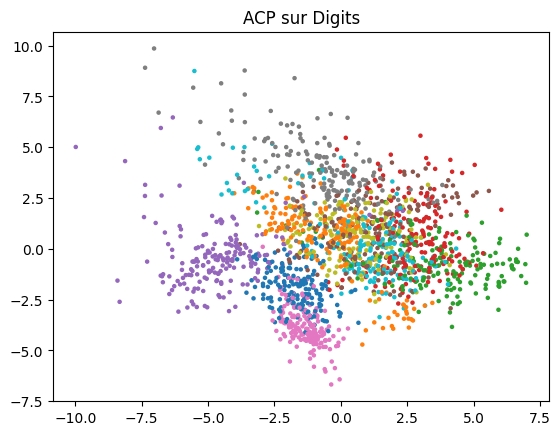

In [21]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

t-SNE construit une représentation en basse dimension qui tente de préserver les voisinages probabilistes. Les probabilités de voisinage en haute dimension sont rapprochées de celles de la projection via une divergence de Kullback-Leibler. perplexity, learning_rate, init et random_state sont des hyperparamètres. Atouts : visualisation de structures locales complexes ; utile exploratoirement. Limites : coût élevé, non-déterminisme possible et distances globales trompeuses ; ce n’est pas un prédicteur.

### Schéma explicatif

```text
Distances locales → probabilités de voisinage → optimisation KL → projection 2D
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Exploration de profils clients ou de familles de produits avant une étude de segmentation. Visualisation de dossiers ou transactions atypiques. Peu approprié pour mesurer des distances globales ou produire une transformation stable de nouveaux points. Métriques : conservation des voisinages et stabilité entre graines, pas R².

### Analyse de l’expérience Python

Le code projette les 600 premiers Digits avec perplexity=35 et init='pca'. Les couleurs représentent les chiffres connus uniquement pour lire la figure. Comparer perplexity=5,35,80 et plusieurs graines montre que les distances entre amas éloignés et leur taille ne sont pas interprétables directement.


In [ ]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

UMAP construit un graphe de voisinage en haute dimension puis optimise une représentation basse dimension qui conserve surtout sa structure locale, avec un compromis global. n_neighbors règle l’échelle du voisinage ; min_dist contrôle la compacité minimale des points ; metric et random_state sont aussi importants. Atouts : rapide et souvent bon pour visualiser de grandes structures ; conserve des voisinages. Limites : résultat dépendant des paramètres ; distances et densités visuelles ne sont pas automatiquement quantitatives.

### Schéma explicatif

```text
Graphe de voisins → ensemble flou local → optimisation de la projection → carte 2D
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Explorer des segments de clients, produits ou itinéraires. Visualiser des milliers de profils avant un clustering. Peu approprié pour une conclusion causale ou une mesure globale sans validation. Métriques : conservation des k-plus-proches-voisins, stabilité et analyse downstream.

### Analyse de l’expérience Python

La cellule utilise 600 Digits, n_neighbors=20 et min_dist=.15. Une figure colorée par chiffre sert à l’interprétation visuelle, pas à l’apprentissage. Comparer n_neighbors=5/20/50 et min_dist=.01/.15/.5 permet d’observer local versus global et amas compacts versus dispersés.


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


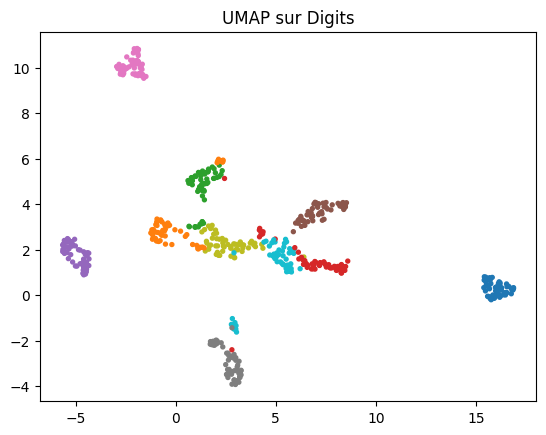

In [22]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Isolation Forest détecte les anomalies en isolant les observations par des séparations aléatoires. Une anomalie est isolée en peu de divisions ; le score dépend de la longueur moyenne des chemins dans les arbres. contamination est un hyperparamètre indiquant la proportion attendue ; n_estimators contrôle le nombre d’arbres. Atouts : non supervisé et efficace en dimension élevée ; ne nécessite pas de modèle de normalité. Limites : anomalies contextuelles difficiles ; contamination influence fortement les alertes et anomalie ne signifie pas erreur.

### Schéma explicatif

```text
Échantillons aléatoires → séparations aléatoires → chemins courts → score d’anomalie → alerte
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Finance : alerter sur des transactions inhabituelles. Logistique : repérer des expéditions atypiques. Peu approprié si les anomalies sont définies par une règle métier connue ou si l’on ne peut pas examiner les alertes. Métriques : précision/rappel si labels fiables, sinon taux d’alerte, stabilité et revue experte.

### Analyse de l’expérience Python

Le modèle utilise contamination=.05 et 150 arbres sur Wine projeté, puis affiche le nombre et les indices des observations prédites −1. Cela ne prouve pas qu’elles sont erronées ou frauduleuses. Comparer contamination=.01,.05,.10 et n_estimators=50,150 documente le volume et la stabilité des alertes.


In [23]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

Nombre de vins atypiques: 9 Indices (extrait): [  3  14  18  59  80 115 146 158 177]


## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Un bandit associe à chaque action ou bras une récompense aléatoire inconnue. L’objectif est de maximiser la récompense cumulée en arbitrant exploration et exploitation. L’estimation empirique d’un bras a est Qₜ(a)=Sₜ(a)/Nₜ(a), avec S la somme des gains et N le nombre de choix. Les probabilités de récompense sont inconnues ; la politique est l’hyperparamètre/stratégie. Atouts : décision en ligne et adaptation ; formulation simple. Limites : pas d’état ni dynamique ; regret et non-stationnarité doivent être considérés.

### Schéma explicatif

```text
Choisir un bras → observer une récompense → mettre à jour moyenne → choisir à nouveau
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Marketing : choisir une campagne ou recommandation. Finance/gestion : allouer progressivement un budget entre stratégies. Peu approprié si les décisions ont des conséquences longues et des états complexes. Métriques : récompense cumulée, regret, taux de sélection du meilleur bras et variance entre graines.

### Analyse de l’expérience Python

La cellule simule quatre bras de probabilités [.15,.4,.6,.75] et les choisit tour à tour pendant 800 pas. Les estimations convergent vers les fréquences générées, mais ce n’est pas un jeu de données réel. Modifier le nombre de tours ou utiliser une politique epsilon-greedy permet de comparer exploration, regret et rapidité de découverte.


In [24]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

Probabilités estimées: [0.205 0.335 0.605 0.765]


## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Epsilon-greedy choisit aléatoirement un bras avec probabilité ε et exploite l’estimation courante du meilleur bras avec probabilité 1−ε. L’estimation empirique est mise à jour après chaque récompense. ε est un hyperparamètre ; il peut être constant ou décroissant. Atouts : extrêmement simple et garantit une exploration minimale ; facile à implémenter. Limites : exploration uniforme parfois inefficace ; choix d’un ε fixe délicat et regret non optimal face à des politiques optimistes ou bayésiennes.

### Schéma explicatif

```text
Estimations initiales → tirage exploration ε ou exploitation 1−ε → récompense → mise à jour
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

A/B testing de campagnes, recommandations et choix de canaux commerciaux. Allocation adaptative d’actions logistiques. Peu approprié si le contexte de l’utilisateur ou l’état du système est indispensable. Métriques : récompense cumulée, regret, meilleur bras trouvé et variance.

### Analyse de l’expérience Python

Le code utilise ε=.15 durant 1200 tours, avec une initialisation lissée (sommes+1)/(comptes+2). Il affiche le nombre de choix et les estimations. Comparer ε=0, .15 et .4 montre respectivement exploitation, compromis et exploration ; répéter plusieurs graines est nécessaire car les récompenses sont aléatoires.


In [25]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

Nombre de choix: [  55   53   44 1048] Estimations: [0.182 0.377 0.614 0.751]


## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

Q-learning apprend une fonction d’action-valeur Q(s,a) et suit une politique off-policy. Sa mise à jour est Q(s,a)←Q(s,a)+α[r+γ maxₐ′Q(s′,a′)−Q(s,a)], où α est le taux d’apprentissage, γ l’actualisation et r la récompense. Le max représente la meilleure action future estimée, indépendamment de l’action explorée. Atouts : simple et converge dans certains environnements tabulaires ; politique optimale greedy. Limites : table impossible pour grands espaces ; exploration et réglages sensibles.

### Schéma explicatif

```text
État s → action ε-greedy → récompense et s′ → cible de Bellman avec max → mise à jour Q
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Gestion : ordonnancement adaptatif sous états discrets. Logistique : choix d’actions dans une simulation de transport. Peu approprié aux états continus ou très nombreux sans approximation. Métriques : récompense moyenne par épisode, taux de réussite, longueur des épisodes et variance entre graines.

### Analyse de l’expérience Python

Le code entraîne une table de taille (états Taxi × actions) pendant 3000 épisodes, avec α=.2, γ=.96 et ε décroissant. L’affichage de Q[0] est un diagnostic, pas une mesure de performance. Comparer α=.1/.2, γ=.9/.96 et une exploration plus longue ; évaluer ensuite sur épisodes sans exploration pour mesurer le taux de réussite.


In [ ]:
# Q-learning manuel sur Taxi-v3 : exploration epsilon-greedy
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

SARSA est un algorithme de contrôle on-policy : il met à jour Q avec l’action suivante effectivement choisie par la politique. La cible est r+γQ(s′,a′), sauf état terminal. α, γ et le calendrier ε sont des hyperparamètres. Contrairement à Q-learning, SARSA tient compte du comportement exploratoire, ce qui peut produire une politique plus prudente. Atouts : cohérent avec la politique exécutée ; adapté quand l’exploration comporte un risque. Limites : dépend de la politique ; apprentissage tabulaire et sensibilité aux réglages.

### Schéma explicatif

```text
s,a → récompense,s′ → choisir réellement a′ → cible r+γQ(s′,a′) → mise à jour
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Navigation logistique où l’exploration coûte cher ; allocation de ressources sous risque. Peu approprié pour grands espaces continus sans approximation. Métriques : récompense cumulée, taux de réussite, coût des épisodes et dispersion entre graines.

### Analyse de l’expérience Python

La cellule entraîne SARSA sur Taxi-v3 avec 3000 épisodes, α=.2, γ=.96 et ε décroissant. Q[0] permet seulement d’inspecter les valeurs apprises. Comparer SARSA à Q-learning avec mêmes graines, puis varier ε minimal, permet d’étudier l’effet on-policy ; une évaluation sans exploration est nécessaire pour comparer les politiques.


In [ ]:
# SARSA manuel sur Taxi-v3 (on-policy)
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
def choisir_action(etat,epsilon):
    return int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400);action=choisir_action(etat,epsilon)
    for pas in range(200):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suiv=choisir_action(suivant,epsilon)
        cible=recompense+(0 if termine else .96*Q[suivant,action_suiv])
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat,action=suivant,action_suiv
        if termine or tronque:break
print('SARSA Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

### Présentation

DQN approxime Q(s,a) par un réseau neuronal au lieu d’une table. La cible de Bellman est y=r+γ maxₐ′Q_target(s′,a′) pour une transition non terminale, et y=r sinon. Les poids du réseau en ligne sont appris ; le réseau cible, sa fréquence de copie, le replay buffer, batch size et learning rate sont des hyperparamètres/éléments d’entraînement. Atouts : états de grande dimension ; approximation flexible. Limites : instabilité, coût et sensibilité ; cette cellule ne réalise pas un entraînement DQN complet.

### Schéma explicatif

```text
état → réseau en ligne Q(s,·) → action → transition → replay buffer → réseau cible → perte TD
```

Le schéma se lit de gauche à droite : les données ou l’état entrent dans le mécanisme d’apprentissage, puis la sortie est produite. Il s’agit d’un schéma original de synthèse réalisé pour ce notebook ; aucune figure externe n’est reproduite.

### Contextes d’utilisation

Contrôle logistique ou allocation séquentielle dans un environnement simulé ; pilotage de stocks avec état vectoriel. Peu approprié si une table suffit ou si les récompenses sont trop rares sans conception d’exploration. Métriques : récompense cumulée, taux de réussite, stabilité entre graines et coût de calcul.

### Analyse de l’expérience Python

La cellule calcule quatre cibles Bellman avec γ=.9 à partir de tableaux déjà fournis. Elle n’entraîne ni réseau, ni mémoire de rejeu : aucune performance DQN ne peut donc être conclue. Une variation de γ modifierait les cibles ; un véritable essai devrait ajouter réseau en ligne/cible, replay buffer, évaluation séparée et plusieurs graines.


In [ ]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [27]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x=X_reg[:,2].copy();x=(x-x.mean())/x.std();y=y_reg.copy()
poids=0.;biais=y.mean();pas=.015
for iteration in range(3000):
    erreur=poids*x+biais-y
    poids-=pas*2*np.mean(erreur*x)
    biais-=pas*2*np.mean(erreur)
print('Manuel:',round(poids,3),round(biais,3))
from sklearn.linear_model import LinearRegression
modele_ref=LinearRegression().fit(x.reshape(-1,1),y)
print('Scikit-learn:',modele_ref.coef_.round(3),round(modele_ref.intercept_,3))

Manuel: 45.16 152.133
Scikit-learn: [45.16] 152.133


In [28]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs=X_clu.copy();k=3;generateur=np.random.default_rng(GRAINE)
centroides=valeurs[generateur.choice(len(valeurs),size=k,replace=False)].copy()
for iteration in range(100):
    distances=((valeurs[:,None,:]-centroides[None,:,:])**2).sum(axis=2)
    groupes=distances.argmin(axis=1)
    nouveaux=np.array([valeurs[groupes==j].mean(axis=0) if np.any(groupes==j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux,centroides):break
    centroides=nouveaux
inertie=np.sum((valeurs-centroides[groupes])**2)
from sklearn.cluster import KMeans
reference=KMeans(n_clusters=k,n_init=15,random_state=GRAINE).fit(valeurs)
print('Inertie manuelle:',round(inertie,2),'Inertie sklearn:',round(reference.inertia_,2))
# Attention : K-means est sensible à l'initialisation ; les deux inerties peuvent différer.

Inertie manuelle: 260.02 Inertie sklearn: 259.51


Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.

(https://colab.research.google.com/assets/colab-badge.svg)](https://github.com/gueye-awaencg-netizen/Gueye_Awa_CC-partieA_fin2/blob/main/CC_Partie_A_reponses_Partie_A.ipynb)